# Sobrecarga no Prism: (2026-10-22)

## Como reproduzir

| O quê | Script |
| --- | --- |
| Passos `ovl_mem`, `ovl_phases`, `ovl_kv`, `ovl_compute` (servidor, config dos modelos, `nvidia-smi` a cada 1 s) | [`polyaxon/run_examples.sh`](../polyaxon/run_examples.sh) |
| Gerador de carga (chegadas abertas, popularidade uniforme, saída de tamanho exato) | [`polyaxon/overload_load.py`](../polyaxon/overload_load.py) |
| Envio do job ao Polyaxon (`kunumi/hpc4ai`, 1 H200) | [`polyaxon/submit.sh`](../polyaxon/submit.sh) |
| Tabela-resumo em texto | [`polyaxon/analyze_ovl.py`](../polyaxon/analyze_ovl.py) |
| Extração dos dados deste notebook (requisições, GPU e eventos dos logs, com tempos relativos ao início da carga) | [`polyaxon/extract_ovl.py`](../polyaxon/extract_ovl.py) |

```bash
# 1. rodar (um job por passo e backend)
PRISM_JOB_ENV="PRISM_STEPS=ovl_mem PRISM_TIMEOUT=2700" polyaxon/submit.sh                    # SGLang
PRISM_IMAGE=gabrielliman/prism:vllm0.30-kvcached0.1.6 \
  PRISM_JOB_ENV="PRISM_BACKEND=vllm PRISM_STEPS=ovl_mem PRISM_TIMEOUT=2700" polyaxon/submit.sh  # vLLM
# outros passos: ovl_phases, ovl_kv, ovl_compute. Ampliação do ovl_compute (PRISM_STEPS=ovl_compute):
#   fine       PRISM_OVL_RATES='10 11.25 12.5 13.75 15 17.5 20'
#   sustained  PRISM_OVL_RATES=18.75 PRISM_OVL_DURATION=600
#   models4    PRISM_OVL_N=4 PRISM_OVL_RATES='5 7.5 10'
#   models6    PRISM_OVL_N=6 PRISM_OVL_POOL=15 PRISM_OVL_RATES='3.333 5 6.667'
#   prefill    PRISM_OVL_LOAD='--input-range 3000 4000 --output-range 16 64' PRISM_OVL_RATES='2.5 5 10 20'
#   decode     PRISM_OVL_LOAD='--input-range 32 128 --output-range 1024 2048' PRISM_OVL_RATES='0.5 1 2 4' PRISM_OVL_DRAIN=600
#   bursty     PRISM_OVL_LOAD='--input-range 256 768 --output-range 128 384 --cv 4' PRISM_OVL_RATES='7.5 10'
# 2. baixar a pasta outputs do job e extrair (um destino por backend; --step-name para a ampliação)
python3 polyaxon/extract_ovl.py <outputs> reports/data/2026-10-21-sobrecarga-real/sglang
python3 polyaxon/extract_ovl.py <outputs> reports/data/2026-10-21-sobrecarga-real/sglang --step-name compute_fine
# 3. executar este notebook a partir de reports/ (pandas, matplotlib)
```

| Cenário | SGLang | vLLM |
| --- | --- | --- |
| `ovl_mem` | `5980af99` | `52b58015` |
| `ovl_phases` | `6af4c960` | `b3d7266e` |
| `ovl_kv` | `8917456e` | `b4b64489` |
| `ovl_compute` | `7e229f2b` | `b82b4409` |
| `fine` | `b96746e9` | `df8f4804` |
| `sustained` | `bf7acc14` | `89ed905e` |
| `models4` / `models6` | `42f04332` / `ccecb916` | `5821f01b` / `e356c017` |
| `prefill` / `decode` | `f3a8d680` / `44bb4970` | `a41e5380` / `380106d9` |
| `bursty` | `0a1dfe4b` | `58effdf6` |

## Convenções

- **Tempo 0 é o início da carga.** A faixa cinza nos gráficos é a janela em que o gerador envia requisições. Depois dela vem o prazo de esvaziamento: requisições que não terminam até o fim do prazo contam como **não atendidas**. Os logs do servidor usam o relógio da máquina; o `extract_ovl.py` posiciona o tempo 0 casando as chegadas do gerador com as admissões do GPU scheduler (erro de ~10 ms).
- **GB** é a unidade do `nvidia-smi` dividida por 1024, como no relatório. O `nvidia-smi` marca 140,4 GB de total; o PyTorch vê 139,7 GB, o valor citado no relatório.
- **SLO**: TTFT ≤ 1 s e TPOT ≤ 100 ms.
- **Duas medidas de vazão.** O relatório chama de "atendido" o número de requisições concluídas dividido pelo tempo total até a última resposta, incluindo o esvaziamento. Isso subestima a vazão quando as saídas são longas: no `ovl_kv` a 0,25 req/s, tudo é atendido com TTFT de 0,3 s, mas o "atendido" fica em 0,74 contra 1,02 req/s oferecidas. Por isso, este notebook usa também a **vazão em regime**: requisições concluídas entre 25% e 100% da janela de carga, divididas por 75% da janela. Abaixo da capacidade, ela fica igual à oferecida. Acima, mostra o teto.

In [1]:
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

DATA = pathlib.Path("data/2026-10-21-sobrecarga-real")
NOME = {"sglang": "SGLang", "vllm": "vLLM"}
COR = {"sglang": "#2a78d6", "vllm": "#eb6834"}
AZUIS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # passos ordinais do azul do SGLang
LARANJAS = ["#f5a582", "#eb6834", "#b8451c", "#7a2a0e"]
TINTA, TINTA2, GRADE, JANELA = "#0b0b0b", "#52514e", "#e4e3df", "#f1f0ec"
ERRO = "#e34948"
EV = {  # eventos dos logs: cor, marcador, legenda
    "activate": ("#1baf7a", "^", "ativação pedida pelo controlador"),
    "evict": ("#6250d6", "v", "despejo por ociosidade"),
    "kv_oom": (ERRO, "x", "kvcached sem memória (ativação falhou)"),
    "oom": (ERRO, "X", "worker sem memória (torch OOM)"),
    "retract": ("#eda100", "|", "SGLang retirou requisições (falta de KV)"),
}
KV_POR_TOKEN_GB = 32 * 8 * 128 * 2 * 2 / 2**30  # Llama-3.1-8B: camadas x cabeças KV x dim x (K, V) x bf16
PESOS_8B_GB = 15.0

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRADE, "grid.linewidth": 0.6, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "font.size": 9.5, "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 30)


def niveis(backend, passo):
    return sorted((d.name[4:] for d in (DATA / backend / passo).glob("rate*")), key=float)


def nivel(backend, passo, rate):
    d = DATA / backend / passo / f"rate{rate}"
    req = pd.read_csv(d / "requests.csv", dtype={"error": str, "model": str})
    req["fim"] = req.arrival + req.latency
    ev = pd.read_csv(d / "events.csv", dtype={"model": str, "value": str}).fillna({"model": "", "value": ""})
    return {"s": json.load(open(d / "summary.json")), "req": req, "gpu": pd.read_csv(d / "gpu.csv"), "ev": ev,
            "backend": backend, "passo": passo, "rate": rate}


def config(backend, passo):
    return json.load(open(DATA / backend / passo / "config.json"))


def eventos(lv, kind):
    return lv["ev"][lv["ev"].kind == kind]

In [2]:
def metricas(lv):
    s, req, ev = lv["s"], lv["req"], lv["ev"]
    dur = s["args"]["duration"]
    ok = req[req.status == "ok"]
    regime = ok[(ok.fim >= 0.25 * dur) & (ok.fim < dur)]
    k = ev.kind.value_counts()
    return {
        "backend": NOME[lv["backend"]], "req/s por modelo": float(lv["rate"]),
        "oferecido": s["offered_rps"], "atendido": s["served_rps"], "em regime": len(regime) / (0.75 * dur),
        "atendidas": f'{s["ok"]} / {s["sent"]}', "não atendidas": s["unserved"], "falhas": s["failed"],
        "TTFT p50 (s)": s["ttft_p50"], "TTFT p99 (s)": s["ttft_p99"], "TPOT médio (ms)": 1000 * s["tpot_mean"],
        "SLO": s["slo_attainment"], "GPU pico (GB)": lv["gpu"].used_gb.max(),
        "ativações": int(k.get("activate", 0)), "despejos": int(k.get("evict", 0)),
        "não coube": int(k.get("no_fit", 0)),
        "retiradas": int(pd.to_numeric(eventos(lv, "retract").value).sum()),
    }


def tabela(passo, colunas, backends=("sglang", "vllm")):
    linhas = [metricas(nivel(b, passo, r)) for b in backends for r in niveis(b, passo)]
    df = pd.DataFrame(linhas)[["backend", "req/s por modelo"] + colunas]
    for c in df.columns:
        if c == "SLO":
            df[c] = df[c].map(lambda x: f"{100 * x:.1f}%")
        elif c == "GPU pico (GB)":
            df[c] = df[c].map(lambda x: f"{x:.1f}")
        elif df[c].dtype.kind == "f" and c != "req/s por modelo":
            df[c] = df[c].map(lambda x: "—" if pd.isna(x) else f"{x:.2f}")
    return df


def andamento(lv, dt=1.0):
    # Requisições no sistema a cada instante: esperando o 1º token (chegada até chegada + TTFT) e gerando
    # (até a última resposta). Não atendidas ficam "esperando" até o fim do prazo; falhas são ignoradas.
    s, req = lv["s"], lv["req"]
    prazo = s["args"]["duration"] + s["args"]["drain"]
    r = req[req.status != "failed"]
    inicio_ger = (r.arrival + r.ttft).fillna(np.inf).values
    fim = r.fim.fillna(prazo).values
    t = np.arange(0, min(prazo, np.nanmax(fim)) + dt, dt)
    chegou = np.searchsorted(np.sort(r.arrival.values), t, side="right")
    comecou = np.searchsorted(np.sort(inicio_ger), t, side="right")
    terminou = np.searchsorted(np.sort(fim), t, side="right")
    return pd.DataFrame({"t": t, "esperando": chegou - comecou, "gerando": comecou - terminou})


def kv_estimado(lv, dt=2.0):
    # KV ocupado pelas requisições em geração: (prompt + tokens já gerados) x 128 KiB, supondo geração linear.
    ok = lv["req"][lv["req"].status == "ok"]
    ini = (ok.arrival + ok.ttft).values
    fim, p, g = ok.fim.values, ok.prompt_len.values, ok.generated.values
    t = np.arange(0, np.nanmax(fim) + dt, dt)
    frac = np.clip((t[:, None] - ini) / np.maximum(fim - ini, 1e-6), 0, 1)
    ativo = (t[:, None] >= ini) & (t[:, None] < fim)
    return pd.DataFrame({"t": t, "kv_gb": ((p + frac * g) * ativo).sum(1) * KV_POR_TOKEN_GB})


def tokens_por_s(lv, dt=5.0):
    # Tokens de saída por segundo: cada requisição gera em ritmo constante entre o 1º e o último token.
    # Tokens de entrada por segundo: o prompt inteiro conta no instante do 1º token.
    ok = lv["req"][lv["req"].status == "ok"]
    ini = (ok.arrival + ok.ttft).values
    fim, g = ok.fim.values, ok.generated.values
    t = np.arange(0, np.nanmax(fim) + dt, dt)
    sobre = np.clip(np.minimum(fim, t[:, None] + dt) - np.maximum(ini, t[:, None]), 0, None)
    saida = (sobre * (g / np.maximum(fim - ini, 1e-6))).sum(1) / dt
    entrada = np.histogram(ini, bins=np.append(t, t[-1] + dt), weights=ok.prompt_len.values)[0] / dt
    return pd.DataFrame({"t": t + dt / 2, "saida": saida, "entrada": entrada})


def janela(ax, lv):
    ax.axvspan(0, lv["s"]["args"]["duration"], color=JANELA, zorder=0, lw=0)

In [3]:
def estados(lv, cfg, t0):
    # Intervalos (início, fim, estado) por modelo, a partir dos eventos do GPU scheduler.
    ev = lv["ev"]
    t_fim = max(lv["gpu"].t.max(), np.nanmax(lv["req"].fim.values))
    out = {}
    for m in cfg:
        nome = m["model_name"]
        estado, desde, ints = ("ativo" if m["init_placements"][0]["on"] else "inativo"), t0, []
        e = ev[(ev.model == nome) & ev.kind.isin(["act_req", "act_ok", "deact_ok"])].sort_values("t")
        for t, kind in zip(e.t, e.kind):
            novo = {"act_req": "ativando", "act_ok": "ativo", "deact_ok": "inativo"}[kind]
            if novo != estado:
                ints.append((max(desde, t0), t, estado))
                estado, desde = novo, t
        ints.append((max(desde, t0), t_fim, estado))
        out[nome] = ints
    return out


def linha_do_tempo(lv, titulo, xlim=None, fases=None, livre=True):
    cfg = config(lv["backend"], lv["passo"])
    modelos = [m["model_name"] for m in cfg]
    req, gpu, ev, cor = lv["req"], lv["gpu"], lv["ev"], COR[lv["backend"]]
    x0 = xlim[0] if xlim else -15
    alturas = [1.1, 0.9, 2.6] if livre else [1.1, 2.6]
    fig, axs = plt.subplots(len(alturas), 1, sharex=True, figsize=(11, 1.9 * sum(alturas)),
                            gridspec_kw={"height_ratios": alturas})
    # (a) memória da GPU
    ax = axs[0]
    janela(ax, lv)
    ax.plot(gpu.t, gpu.used_gb, color=cor)
    total = gpu.total_gb.iloc[0]
    ax.axhline(total, color=TINTA2, ls="--", lw=1)
    ax.text(x0, total, f" total {total:.1f} GB", va="bottom", color=TINTA2, fontsize=8)
    for kind in ("activate", "evict", "kv_oom", "oom"):
        for t in eventos(lv, kind).t:
            ax.axvline(t, color=EV[kind][0], lw=1, alpha=0.8)
    ax.set_ylabel("GB usados")
    ax.set_ylim(0, total * 1.12)
    ax.set_title("Memória da GPU (nvidia-smi); linhas verticais = eventos da legenda")
    # (b) memória livre vista pelo controlador global
    if livre:
        ax = axs[1]
        janela(ax, lv)
        fm = eventos(lv, "free_mem")
        ax.step(fm.t, fm.value.astype(float), where="post", color=TINTA2, lw=1.5)
        ax.axhline(PESOS_8B_GB, color=EV["activate"][0], ls=":", lw=1.2)
        ax.text(x0, PESOS_8B_GB, " pesos de um 8B (15 GB)", va="bottom", color=TINTA2, fontsize=8)
        for t in eventos(lv, "activate").t:
            antes = fm[fm.t <= t + 0.01].value.astype(float)
            if len(antes):
                ax.plot(t, antes.iloc[-1], marker="^", color=EV["activate"][0], ms=8, mec="white", mew=1.5)
        ax.set_ylabel("GB livres")
        ax.set_title("Memória livre que o controlador global viu em cada ciclo (base da decisão de ativar)")
    # (c) estado e respostas de cada modelo
    ax = axs[-1]
    janela(ax, lv)
    est = estados(lv, cfg, x0)
    for y, m in enumerate(modelos):
        if fases:
            for a, b in fases.get(m, []):
                ax.axvspan(a, b, ymin=1 - (y + 1) / len(modelos), ymax=1 - y / len(modelos), color="#dcdad3",
                           lw=0, zorder=0.5)
        for a, b, st in est[m]:
            if st == "ativo":
                ax.barh(y, b - a, left=a, height=0.62, color=cor, alpha=0.28, lw=0, zorder=1)
            elif st == "ativando":
                ax.barh(y, b - a, left=a, height=0.62, facecolor="none", edgecolor="#c98500", hatch="////",
                        lw=0.8, zorder=1)
        r = req[req.model == m]
        ok, nao, falha = r[r.status == "ok"], r[r.status == "unserved"], r[r.status == "failed"]
        ax.plot(ok.fim, np.full(len(ok), y), "|", color=TINTA, ms=7, alpha=0.55, zorder=2)
        ax.plot(nao.arrival, np.full(len(nao), y + 0.22), "x", color=ERRO, ms=3.5, mew=0.9, zorder=2)
        ax.plot(falha.arrival, np.full(len(falha), y - 0.22), ".", color=ERRO, ms=3, zorder=2)
        for kind in ("activate", "evict"):
            e = ev[(ev.kind == kind) & (ev.model == m)]
            ax.plot(e.t, np.full(len(e), y), EV[kind][1], color=EV[kind][0], ms=8, mec="white", mew=1.2, zorder=3)
    ax.set_yticks(range(len(modelos)), modelos)
    ax.set_ylim(len(modelos) - 0.4, -0.6)
    ax.grid(axis="y", visible=False)
    ax.set_title("Estado de cada modelo e respostas recebidas")
    ax.set_xlabel("tempo desde o início da carga (s)")
    if xlim:
        ax.set_xlim(*xlim)
    else:
        ax.set_xlim(x0, None)
    alca = [Patch(color=cor, alpha=0.28, label="ativo"),
            Patch(facecolor="none", edgecolor="#c98500", hatch="////", label="ativando (pedido sem conclusão)"),
            Line2D([], [], marker="|", ls="", color=TINTA, ms=8, label="resposta concluída"),
            Line2D([], [], marker="x", ls="", color=ERRO, label="chegada não atendida"),
            Line2D([], [], marker=".", ls="", color=ERRO, label="chegada que falhou")]
    if fases:
        alca.append(Patch(color="#dcdad3", label="grupo do modelo recebendo carga"))
    alca += [Line2D([], [], marker=EV[k][1], ls="", color=EV[k][0], ms=7, label=EV[k][2])
             for k in ("activate", "evict", "kv_oom", "oom") if len(eventos(lv, k))]
    alca.append(Patch(color=JANELA, label="janela de carga"))
    fig.legend(handles=alca, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.tight_layout(rect=(0, 0.07, 1, 0.97))
    plt.show()

# 1. `ovl_mem`: mais pesos do que cabem na GPU

## Objetivo

Testar o caso que motiva o Prism: **mais modelos do que cabem na GPU, todos com demanda ao mesmo tempo**. Os pesos somados (10 × 15 GB = 151 GB) passam da memória da GPU (139,7 GB), e todos os modelos recebem requisições durante toda a carga, então nenhum fica ocioso. A pergunta é como o plano de controle reage. Ele pode revezar os modelos na GPU, recusar requisições ou deixar alguns modelos sem atendimento. E o servidor pode ou não sobreviver.

## Como a sobrecarga foi montada

- **Modelos:** 10 cópias de `meta-llama/Llama-3.1-8B-Instruct` (`model_1` … `model_10`), cada uma com até 10 GB de KV (`max_memory_pool_size`). As cópias têm nomes diferentes, e o Prism trata cada uma como um modelo distinto.
- **Estado inicial:** `model_1` a `model_6` ativos. Antes da carga, a GPU marca 107,5 GB: 90 GB de pesos mais ~17,5 GB de custo fixo dos 10 workers. Isso deixa ~32 GB livres, o que é o suficiente para mais 2 modelos sem KV nenhum, ou para 1 com folga. Os outros 4 começam inativos, já com tráfego, e por isso o controlador precisa decidir o que fazer com eles.
- **Carga:** Poisson, 0,2 e 0,5 req/s **por modelo** (2 e 5 req/s no total), prompts de 256–1.024 tokens, saídas de 128–512, janela de 300 s e prazo de esvaziamento de 300 s.
- **Servidor:** flags do exemplo 3 do README (kvcached, GPU scheduler, controlador `simple-global`, worker pool com 10 workers).

In [4]:
cfg = config("sglang", "ovl_mem")
pd.DataFrame([{"modelo": m["model_name"], "ativo no início": m["init_placements"][0]["on"],
               "KV máx. (GB)": m["init_placements"][0]["max_memory_pool_size"]} for m in cfg]).T

,0,1,2,3,4,5,6,7,8,9
modelo,model_1,model_2,model_3,model_4,model_5,model_6,model_7,model_8,model_9,model_10
ativo no início,True,True,True,True,True,True,False,False,False,False
KV máx. (GB),10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0


## Gráficos

### SGLang a 0,2 req/s por modelo: fome

São três painéis com o mesmo eixo de tempo:

- **Memória da GPU:** quanto o `nvidia-smi` marca em uso.
- **Memória livre segundo o controlador:** o valor que ele consulta a cada ciclo para decidir se um modelo inativo cabe. Os triângulos marcam as ativações.
- **Estado de cada modelo:** faixa azul = ativo; faixa hachurada = ativação pedida e nunca concluída; traços = respostas concluídas; `x` vermelho = requisição que chegou e nunca foi atendida.

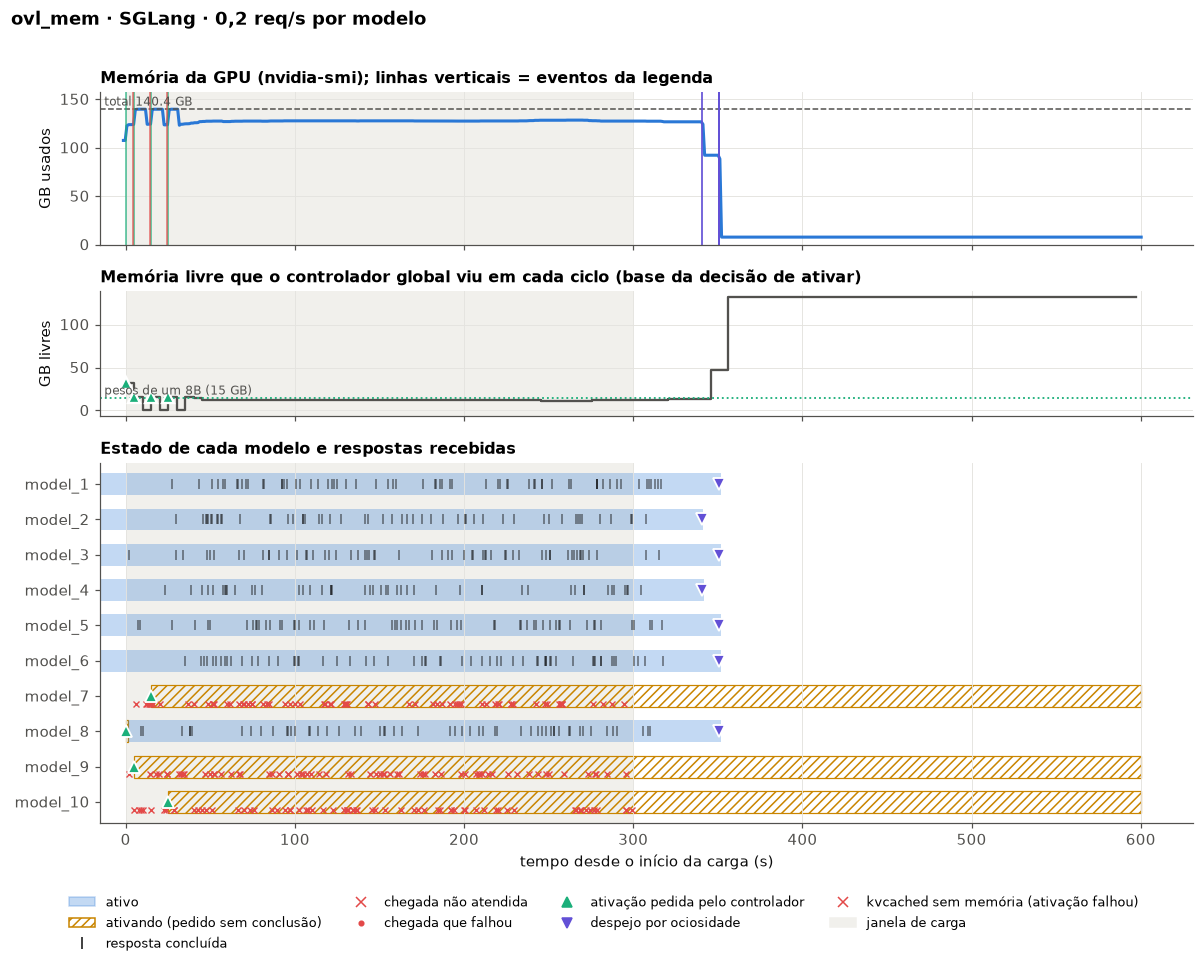

In [5]:
mem02 = nivel("sglang", "ovl_mem", "0.2")
linha_do_tempo(mem02, "ovl_mem · SGLang · 0,2 req/s por modelo")

**O que o gráfico mostra:**

- **Ativações sem folga.** O `model_8` é ativado 0,2 s depois do início da carga, com 32 GB livres, e passa a responder. O `model_9`, o `model_7` e o `model_10` são ativados aos 5, 15 e 25 s com **15,4, 15,3 e 15,8 GB livres**: o suficiente para os 15 GB de pesos, sem nada para o KV (2º painel). Nos três casos, o kvcached do worker não consegue reservar memória para o KV logo em seguida (linhas vermelhas). A memória da GPU fica colada no total durante toda a carga.
- **Falha silenciosa.** Os três ficam "ativando" para sempre (faixa hachurada). Nenhum responde, e todas as suas requisições aparecem como `x` vermelhos.
- **Despejo tardio.** O primeiro despejo só acontece aos ~341 s: 41 s depois do fim da carga, quando os modelos completam 50 s sem requisições. Mesmo com a GPU esvaziada, os três modelos pendurados não voltam, porque o GPU scheduler continua achando que eles estão ativando.

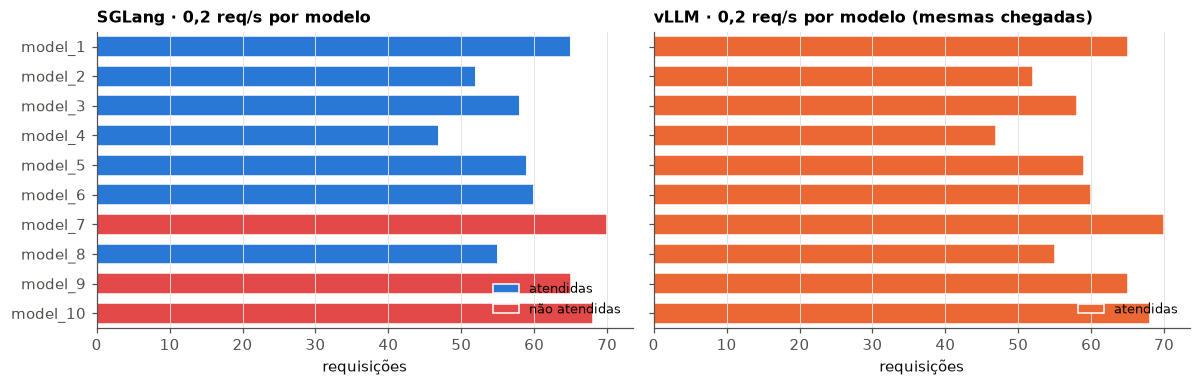

In [6]:
def por_modelo(lv, ax, titulo):
    req = lv["req"]
    modelos = [m["model_name"] for m in config(lv["backend"], lv["passo"])]
    c = req.groupby(["model", "status"]).size().unstack(fill_value=0).reindex(modelos).fillna(0)
    esq = np.zeros(len(c))
    for st, cor, rot in (("ok", COR[lv["backend"]], "atendidas"), ("unserved", ERRO, "não atendidas"),
                         ("failed", "#7a1d1d", "falharam")):
        if st in c:
            ax.barh(range(len(c)), c[st], left=esq, color=cor, height=0.7, label=rot, edgecolor="white", lw=1)
            esq += c[st].values
    ax.set_yticks(range(len(c)), c.index)
    ax.set_ylim(len(c) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("requisições")
    ax.set_title(titulo)
    ax.legend(loc="lower right")


fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
por_modelo(mem02, axs[0], "SGLang · 0,2 req/s por modelo")
por_modelo(nivel("vllm", "ovl_mem", "0.2"), axs[1], "vLLM · 0,2 req/s por modelo (mesmas chegadas)")
fig.tight_layout()
plt.show()

Por modelo, a fome fica concentrada: no SGLang, `model_7`, `model_9` e `model_10` não têm nenhuma requisição atendida, e os outros 7 têm todas. No vLLM, com as mesmas chegadas, tudo termina atendido, mas veja na seção do vLLM quando isso acontece.

### SGLang a 0,5 req/s por modelo: o servidor cai

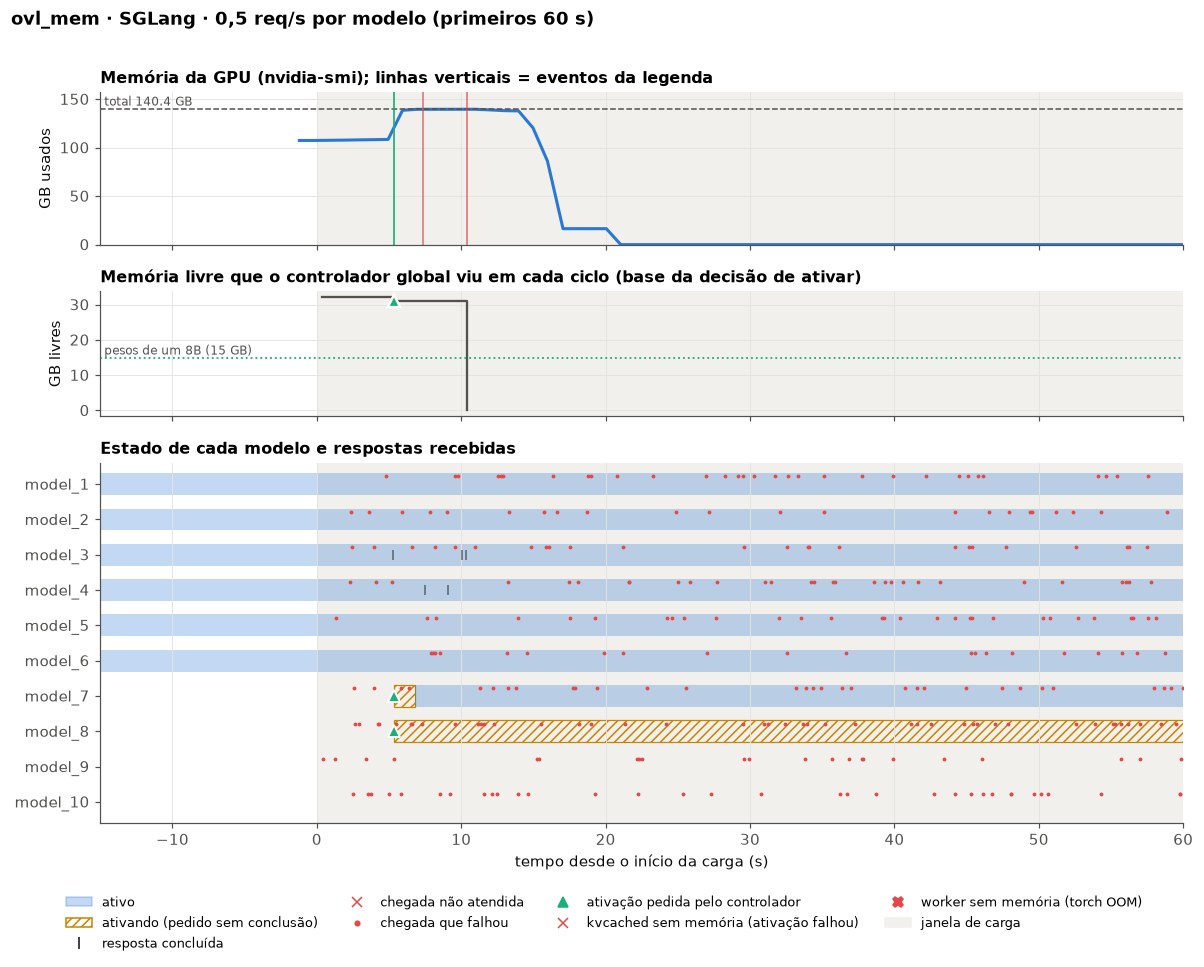

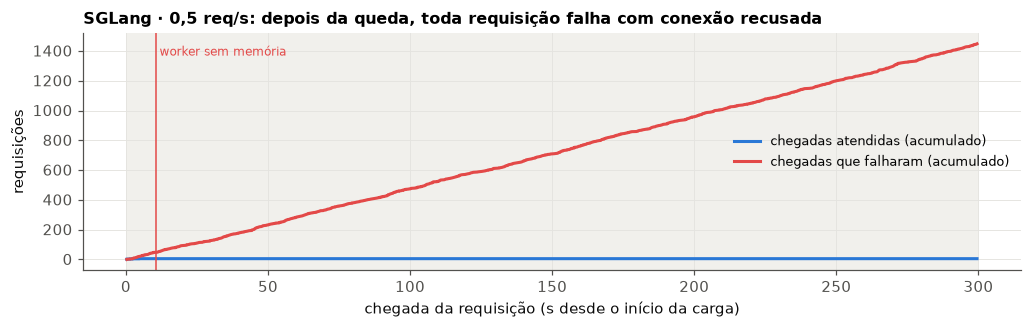

In [7]:
mem05 = nivel("sglang", "ovl_mem", "0.5")
linha_do_tempo(mem05, "ovl_mem · SGLang · 0,5 req/s por modelo (primeiros 60 s)", xlim=(-15, 60))

r = mem05["req"].sort_values("arrival")
fig, ax = plt.subplots(figsize=(11, 2.8))
janela(ax, mem05)
ax.plot(r.arrival, (r.status == "ok").cumsum(), color=COR["sglang"], label="chegadas atendidas (acumulado)")
ax.plot(r.arrival, (r.status == "failed").cumsum(), color=ERRO, label="chegadas que falharam (acumulado)")
for t in eventos(mem05, "oom").t:
    ax.axvline(t, color=ERRO, lw=1)
    ax.text(t, ax.get_ylim()[1] * 0.9, " worker sem memória", color=ERRO, fontsize=8)
ax.set_xlabel("chegada da requisição (s desde o início da carga)")
ax.set_ylabel("requisições")
ax.set_title("SGLang · 0,5 req/s: depois da queda, toda requisição falha com conexão recusada")
ax.legend(loc="center right")
plt.show()

A 0,5 req/s, o controlador ativa o `model_7` e o `model_8` **juntos** aos 5 s, com 31,0 GB livres para 30 GB de pesos. A memória sobe até o total, o kvcached falha aos ~7 s, e aos ~10 s um worker morre com `torch.OutOfMemoryError`. Entre 15 e 20 s, a memória da GPU vai a zero: o servidor inteiro caiu. Das 1.453 requisições, 5 são atendidas. Das 1.448 falhas, 47 estavam em andamento na queda (`Server disconnected`), e 1.401 chegaram com o servidor fora do ar (`Cannot connect to host`).

## Tabelas

In [8]:
tabela("ovl_mem", ["atendidas", "não atendidas", "falhas", "TTFT p50 (s)", "TTFT p99 (s)", "SLO",
                   "GPU pico (GB)", "ativações", "despejos", "não coube", "retiradas"])

,backend,req/s por modelo,atendidas,não atendidas,falhas,TTFT p50 (s),TTFT p99 (s),SLO,GPU pico (GB),ativações,despejos,não coube,retiradas
0,SGLang,0.2,396 / 599,203,0,0.16,14.24,60.8%,139.7,4,7,5,4
1,SGLang,0.5,5 / 1453,0,1448,0.09,0.13,0.3%,139.7,2,0,4,1
2,vLLM,0.2,599 / 599,0,0,2.71,338.34,45.9%,135.5,4,9,136,0
3,vLLM,0.5,1453 / 1453,0,0,94.63,357.64,14.2%,136.6,4,10,143,0


## Conclusões e limitações do Prism

- **Ele não reveza modelos ocupados.** A única regra de despejo do `simple_global` é a ociosidade: mais de 50 s sem requisição e fila vazia (`MODEL_IDLE_THRESHOLD = 50`, fixo no código, em `scheduling/policy/simple_global.py:185`). Com todos os modelos recebendo tráfego, ninguém é despejado, e quem ficou de fora passa fome enquanto a carga durar. É exatamente a sobrecarga que o artigo motiva, e a política atual não a resolve.
- **Ele ativa sem reservar memória para o KV.** A decisão compara os pesos (15 GB) com a memória livre do instante (`simple_global.py:726`). Aqui, ativou modelos com 0,3 a 1 GB de folga. Os modelos ativos continuam aumentando o KV, então a ativação perde a disputa por memória logo depois.
- **No SGLang, a ativação que falha fica pendurada sem aviso.** O GPU scheduler mantém o modelo em `activating` e continua enfileirando requisições para ele. O controlador o trata como ativo, então ele não aparece como "não coube" (só 5 avisos no SGLang, contra 136 no vLLM) e nunca é despejado. Nada tenta de novo.
- **No SGLang, a falta de memória derruba o servidor inteiro.** Basta um worker sem memória para todos os modelos ficarem fora do ar, inclusive os que estavam funcionando.

**Limitações do teste.** Uma execução por nível, numa única H200. As cópias do mesmo checkpoint representam modelos diferentes, o que não muda o uso de memória nem de computação. A quantidade de modelos ativos no início (6) não foi variada.

## Por que o vLLM se comporta diferente

O plano de controle é o mesmo nos dois backends (controlador, GPU scheduler, regra dos 50 s), e as decisões também: no vLLM, o controlador ativa os mesmos modelos nos mesmos instantes. A diferença está no **worker**, quando uma ativação não cabe.

- No SGLang 0.3.4, o kvcached do fork `prism/shm` falha o `cuMemCreate`, e a ativação morre sem avisar o GPU scheduler.
- No vLLM, a ativação **fica bloqueada até haver memória**. Pelos logs, o motor do `model_9` é criado em 1,8 s, aos ~7 s, mas a etapa seguinte (aplicar o limite de KV do kvcached 0.1.6) só termina 337 s depois, quando os despejos por ociosidade liberam memória. A partir daí os três modelos esvaziam a fila acumulada.

O resultado no vLLM é **latência enorme, mas sem perda nem queda**: TTFT P99 de 338 s, e 100% das requisições atendidas. A política de despejo continua sendo a mesma, então a fome continua durante a carga: o vLLM apenas a converte em espera, em vez de perda.

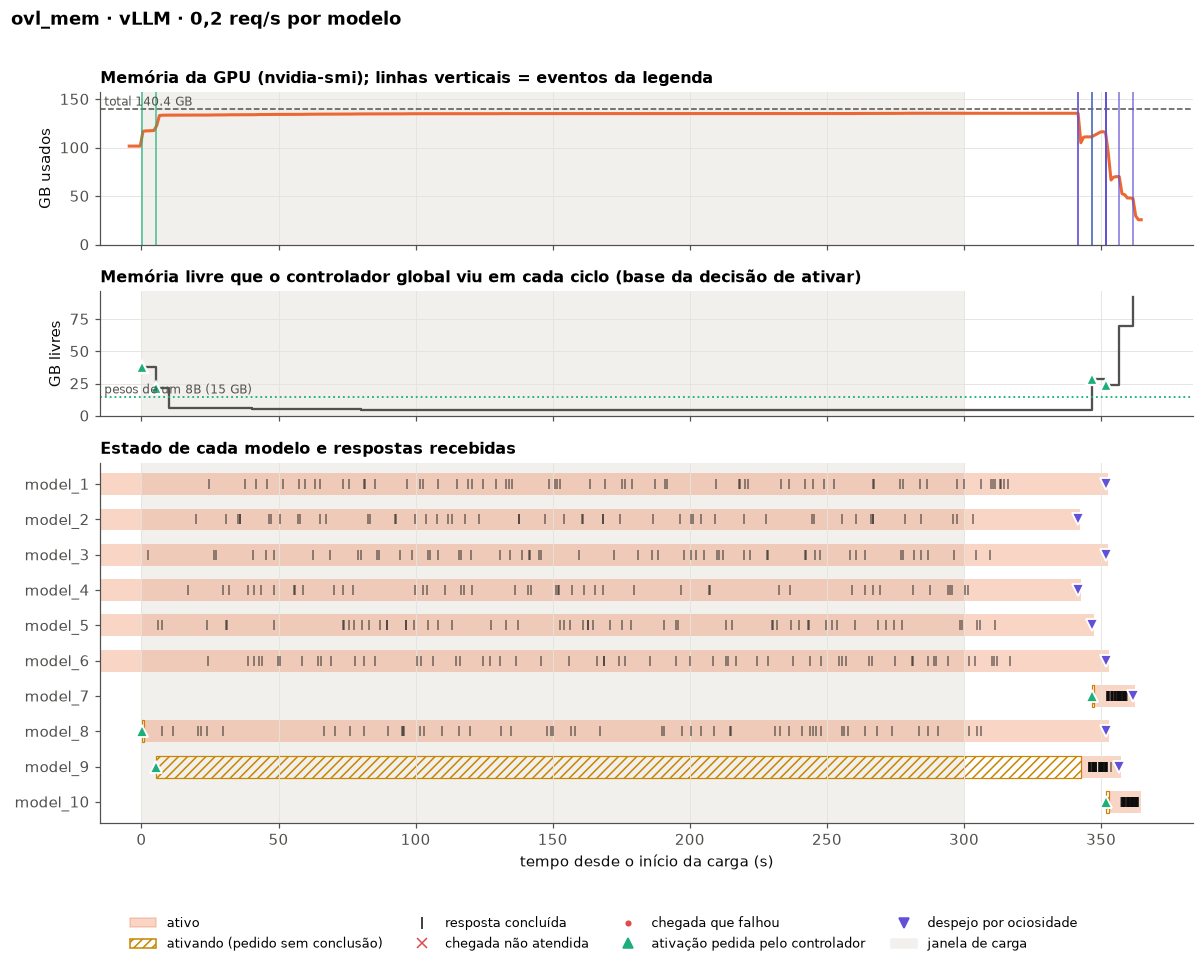

In [9]:
linha_do_tempo(nivel("vllm", "ovl_mem", "0.2"), "ovl_mem · vLLM · 0,2 req/s por modelo")

# 2. `ovl_phases`: rodízio de grupos

## Objetivo

Verificar o caso para o qual o Prism foi desenhado: **compartilhamento da GPU no tempo**. Os modelos não cabem todos de uma vez, mas a demanda se alterna, então em cada momento uma parte deles fica ociosa. O Prism deveria despejar os ociosos e ativar os que passaram a receber tráfego, sem perder requisições. O que queremos medir é quanto custa cada troca.

## Como a sobrecarga foi montada

- **Modelos:** os mesmos 10 × 8B do `ovl_mem` (151 GB de pesos), com até 10 GB de KV cada.
- **Grupos:** A = `model_1`–`model_5` e B = `model_6`–`model_10`. O grupo A recebe tráfego em [0, 150) s e [300, 450) s; o grupo B em [150, 300) s e [450, 600) s. Começam ativos os 5 do grupo A.
- **Carga:** 0,5 req/s por modelo enquanto o grupo está ligado, com prompts e saídas iguais aos do `ovl_mem`. Janela de 600 s, com 3 trocas de grupo.

## Gráficos

Na linha do tempo, o fundo cinza de cada linha marca quando o grupo daquele modelo está recebendo carga.

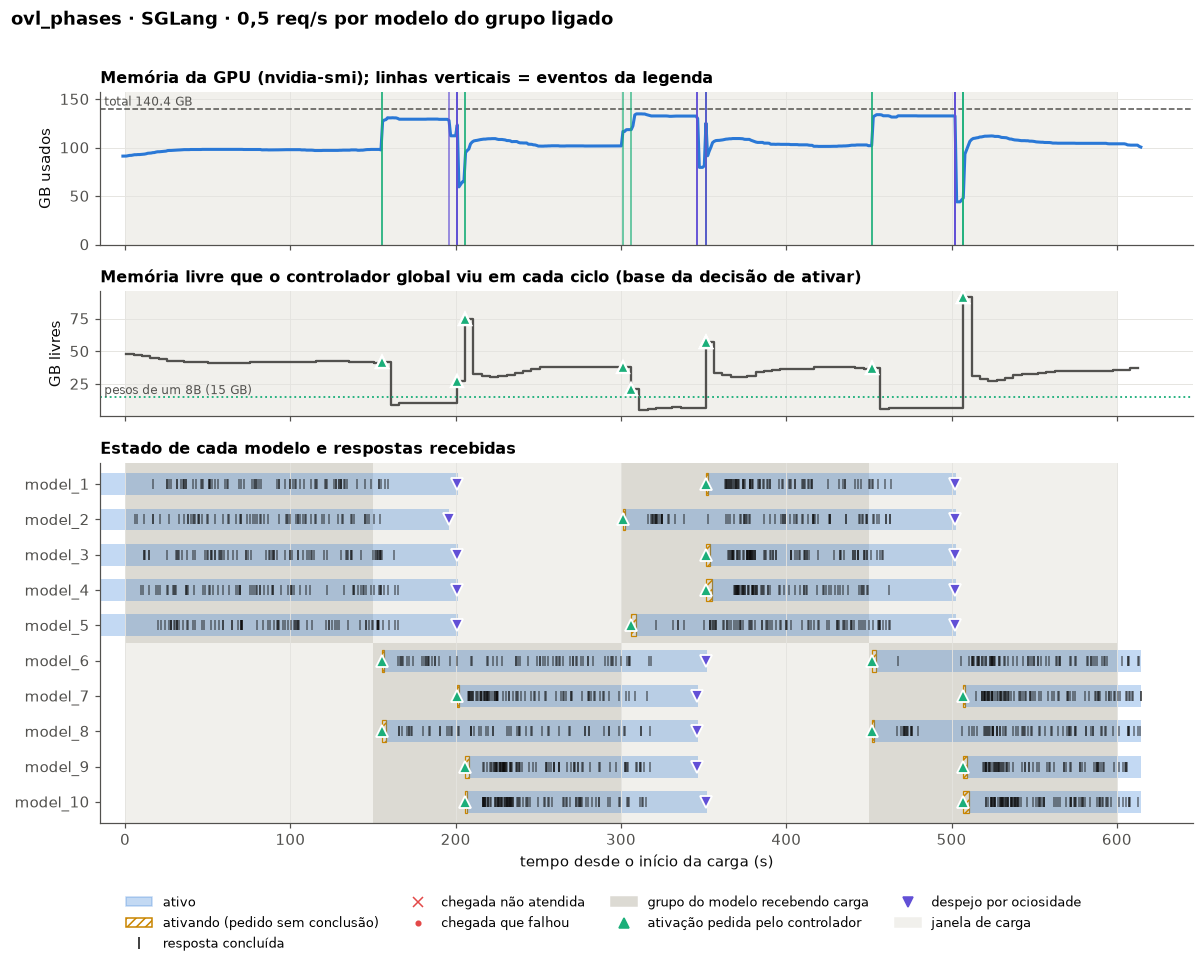

In [10]:
def fases_por_modelo(lv):
    a = lv["s"]["args"]
    ms, g, fase, dur = a["models"], a["groups"], a["phase"], a["duration"]
    n = len(ms)
    out = {}
    for i in range(g):
        for m in ms[i * n // g:(i + 1) * n // g]:
            out[m] = [(k * fase, min((k + 1) * fase, dur)) for k in range(int(np.ceil(dur / fase))) if k % g == i]
    return out


ph = nivel("sglang", "ovl_phases", "0.5")
linha_do_tempo(ph, "ovl_phases · SGLang · 0,5 req/s por modelo do grupo ligado", fases=fases_por_modelo(ph))

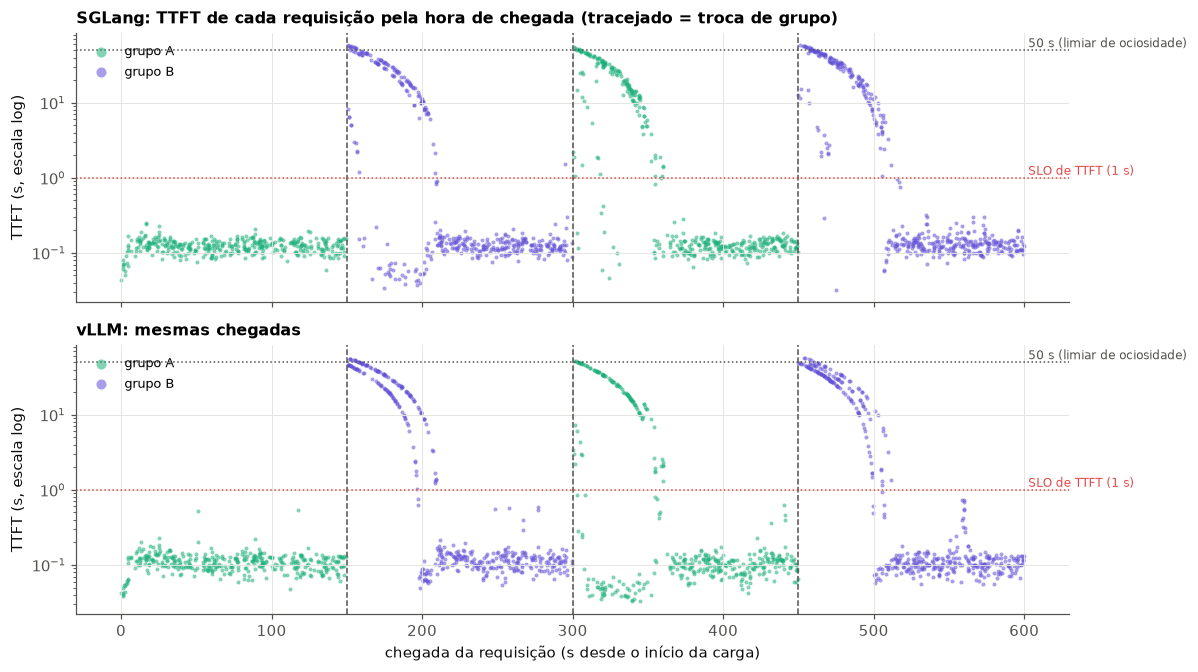

In [11]:
def ttft_no_tempo(lv, ax, titulo):
    a = lv["s"]["args"]
    fases = fases_por_modelo(lv)
    grupo = {m: ("A" if fases[m][0][0] == 0 else "B") for m in fases}
    ok = lv["req"][lv["req"].status == "ok"]
    for g, cor in (("A", "#1baf7a"), ("B", "#6250d6")):
        r = ok[ok.model.map(grupo) == g]
        ax.scatter(r.arrival, r.ttft, s=7, color=cor, alpha=0.55, lw=0, label=f"grupo {g}")
    for k in range(1, int(a["duration"] // a["phase"])):
        ax.axvline(k * a["phase"], color=TINTA2, ls="--", lw=1)
    ax.axhline(1, color=ERRO, ls=":", lw=1)
    ax.text(a["duration"], 1, " SLO de TTFT (1 s)", color=ERRO, fontsize=8, va="bottom")
    ax.axhline(50, color=TINTA2, ls=":", lw=1)
    ax.text(a["duration"], 50, " 50 s (limiar de ociosidade)", color=TINTA2, fontsize=8, va="bottom")
    ax.set_yscale("log")
    ax.set_ylabel("TTFT (s, escala log)")
    ax.set_title(titulo)
    ax.legend(loc="upper left", markerscale=2.5)


fig, axs = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, sharey=True)
ttft_no_tempo(ph, axs[0], "SGLang: TTFT de cada requisição pela hora de chegada (tracejado = troca de grupo)")
ttft_no_tempo(nivel("vllm", "ovl_phases", "0.5"), axs[1], "vLLM: mesmas chegadas")
axs[1].set_xlabel("chegada da requisição (s desde o início da carga)")
fig.tight_layout()
plt.show()

**O que os gráficos mostram:**

- **Cada troca de grupo segue o mesmo padrão.** Os 2 modelos do grupo novo que cabem na memória livre são ativados em segundos. Os outros 3 esperam que os modelos do grupo antigo completem 50 s sem requisições e sejam despejados (na linha do tempo, os modelos antigos continuam ativos ~50 s depois que o seu grupo desliga). Todas as requisições acumuladas são atendidas no momento da ativação. Por isso a primeira requisição após a troca espera ~50 s, as seguintes esperam cada vez menos, e o TTFT forma a curva descendente depois de cada linha tracejada.
- **Fora das transições, o TTFT volta para ~0,1 s.** Nenhuma requisição foi perdida.
- **O custo da troca é a regra dos 50 s, não a cópia dos pesos.** A ativação em si leva ~1 s (pesos vindos da memória compartilhada da CPU). Os ~50 s do P99 são o limiar de ociosidade.

## Tabelas

In [12]:
tabela("ovl_phases", ["atendidas", "TTFT p50 (s)", "TTFT p99 (s)", "SLO", "GPU pico (GB)", "ativações",
                      "despejos", "não coube"])

,backend,req/s por modelo,atendidas,TTFT p50 (s),TTFT p99 (s),SLO,GPU pico (GB),ativações,despejos,não coube
0,SGLang,0.5,1564 / 1564,0.14,53.23,73.3%,134.9,15,15,86
1,vLLM,0.5,1564 / 1564,0.12,50.52,75.5%,139.1,15,15,66


## Conclusões e limitações do Prism

- **Quando a carga se alterna, o Prism compartilha a GPU como prometido.** Foram 15 trocas em 10 min, sem nenhuma requisição perdida e com 73% de SLO no SGLang.
- **A latência de cada troca é fixada pela regra de ociosidade.** O Prism não tem como saber que um grupo "acabou"; ele só espera 50 s sem requisições. Um limiar menor reduziria o P99 das transições, mas aumentaria o vaivém de modelos com tráfego intermitente. E como o limiar é fixo no código, essa troca não pode ser ajustada sem editar a política.
- **Despejar sob demanda resolveria o mesmo problema sem esperar.** Se o controlador despejasse um modelo ocioso há menos de 50 s quando outro modelo com fila não cabe, a transição custaria só a ativação. É a mesma melhoria apontada no `ovl_mem`.

**Limitações do teste.** Uma execução. Os grupos têm tamanho e taxa iguais, e a troca é abrupta. Com troca gradual ou grupos desbalanceados, o comportamento pode ser diferente.

## Por que o vLLM se comporta diferente

Aqui ele **quase não difere** (TTFT P99 de 50,5 s contra 53,2 s, SLO de 75,5% contra 73,3%). O custo está no plano de controle, que é o mesmo nos dois backends: a espera de 50 s para despejar domina, e a velocidade do engine pesa pouco. Também não há ativação falhando, porque cada modelo novo só é ativado depois que um antigo foi despejado.

# 3. `ovl_kv`: o KV não cabe

## Objetivo

Separar a pressão de **memória de KV** da pressão de pesos. Todos os modelos estão ativos desde o início e cabem na GPU, então o controlador não precisa ativar nem despejar ninguém. O que falta é memória para o KV das requisições em andamento. A pergunta é se essa falta derruba o sistema (como no `ovl_mem`), se o engine a absorve, e quanto ela custa em vazão e latência.

## Como a sobrecarga foi montada

- **Modelos:** 4 × 8B, todos ativos. São 60 GB de pesos mais ~10 GB do custo fixo dos workers, o que deixa **~70 GB para KV**. Cada modelo pode usar até 40 GB de KV, então juntos poderiam pedir 160 GB.
- **Requisições pesadas:** prompts de 2.048–4.096 tokens e saídas de 1.024–2.048 (tamanho exato, `ignore_eos`). No Llama 3.1 8B, o KV ocupa 128 KiB por token, ou seja, **0,25–0,75 GB por requisição**, mantidos por toda a geração.
- **Carga:** 0,25, 0,5 e 1 req/s por modelo (1, 2 e 4 req/s no total), janela de 180 s e prazo de 600 s, porque as saídas são longas.

## Gráficos

### Memória da GPU e KV estimado

O KV estimado é calculado só a partir das requisições, sem olhar a GPU: para cada requisição em geração, soma (prompt + tokens já gerados) × 128 KiB. Ele mostra quanto KV a carga realmente pedia em cada instante.

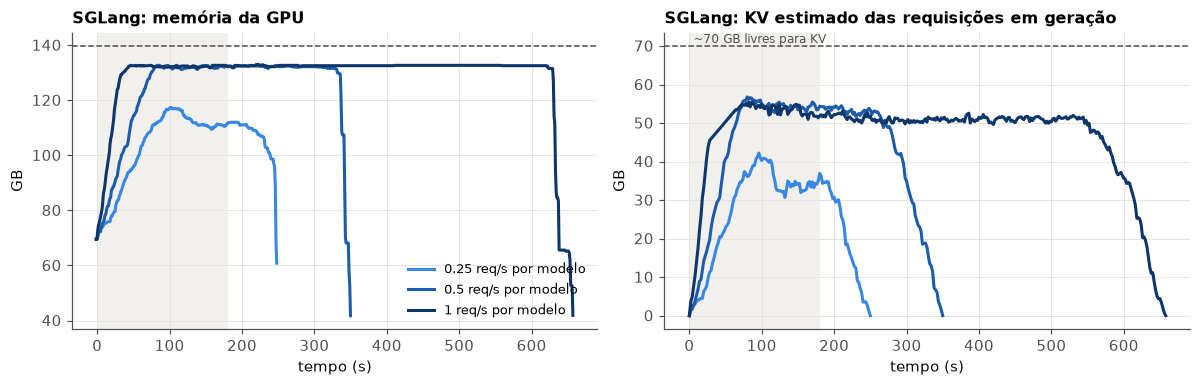

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for i, rate in enumerate(niveis("sglang", "ovl_kv")):
    lv = nivel("sglang", "ovl_kv", rate)
    axs[0].plot(lv["gpu"].t, lv["gpu"].used_gb, color=AZUIS[i + 1], label=f"{rate} req/s por modelo")
    kv = kv_estimado(lv)
    axs[1].plot(kv.t, kv.kv_gb, color=AZUIS[i + 1], label=f"{rate} req/s por modelo")
for ax in axs:
    janela(ax, lv)
    ax.set_xlabel("tempo (s)")
axs[0].axhline(139.7, color=TINTA2, ls="--", lw=1)
axs[0].set_ylabel("GB")
axs[0].set_title("SGLang: memória da GPU")
axs[0].legend(loc="lower right")
axs[1].axhline(70, color=TINTA2, ls="--", lw=1)
axs[1].text(0, 70, " ~70 GB livres para KV", color=TINTA2, fontsize=8, va="bottom")
axs[1].set_ylabel("GB")
axs[1].set_title("SGLang: KV estimado das requisições em geração")
fig.tight_layout()
plt.show()

A 0,25 req/s, o KV estimado fica em ~35–40 GB, e a GPU não enche. A 0,5 e a 1 req/s, a GPU encosta no limite (133 GB), e o KV estimado para num teto de **~52–55 GB**, em vez de acompanhar a carga: o engine não deixa entrar mais requisições do que o KV comporta. O teto fica abaixo dos ~70 GB livres por causa das páginas que o kvcached reserva e não usa e da fragmentação entre os 4 engines.

### Requisições esperando e gerando

Uma requisição está **esperando** da chegada até o primeiro token e **gerando** do primeiro ao último. Os traços amarelos no topo marcam os momentos em que o SGLang retirou requisições do batch por falta de KV (`Decode out of memory`).

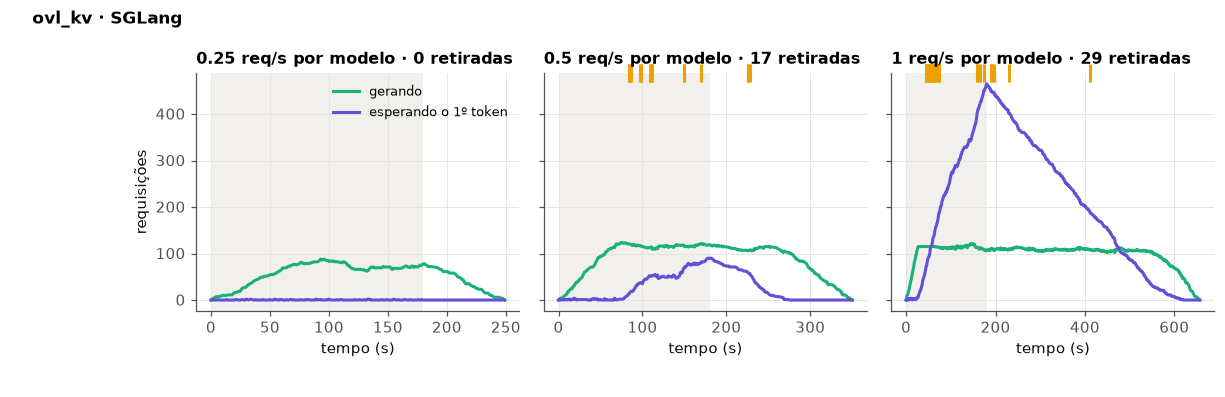

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, rate in zip(axs, niveis("sglang", "ovl_kv")):
    lv = nivel("sglang", "ovl_kv", rate)
    a = andamento(lv)
    janela(ax, lv)
    ax.plot(a.t, a.gerando, color="#1baf7a", label="gerando")
    ax.plot(a.t, a.esperando, color="#6250d6", label="esperando o 1º token")
    rt = eventos(lv, "retract")
    ax.plot(rt.t, np.full(len(rt), 1.0), "|", color=EV["retract"][0], ms=12, mew=2,
            transform=ax.get_xaxis_transform(), clip_on=False)
    ax.set_title(f"{rate} req/s por modelo · {len(rt)} retiradas")
    ax.set_xlabel("tempo (s)")
axs[0].set_ylabel("requisições")
axs[0].legend(loc="upper right")
fig.suptitle("ovl_kv · SGLang", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Este é o gráfico central do cenário.** A 0,5 e a 1 req/s, o número de requisições **gerando** tem um teto: são as que cabem no KV. Todo o excesso vai para **esperando**, que cresce durante a janela e só esvazia no prazo. As retiradas do SGLang acontecem justamente quando o teto é atingido.

### Limite de KV ou de computação?

Se a GPU estivesse sem computação, ela não geraria mais tokens por segundo com outra carga. O gráfico compara os tokens de saída por segundo do `ovl_kv` com os do `ovl_compute` a 25 req/s por modelo, que tem requisições curtas e satura a computação.

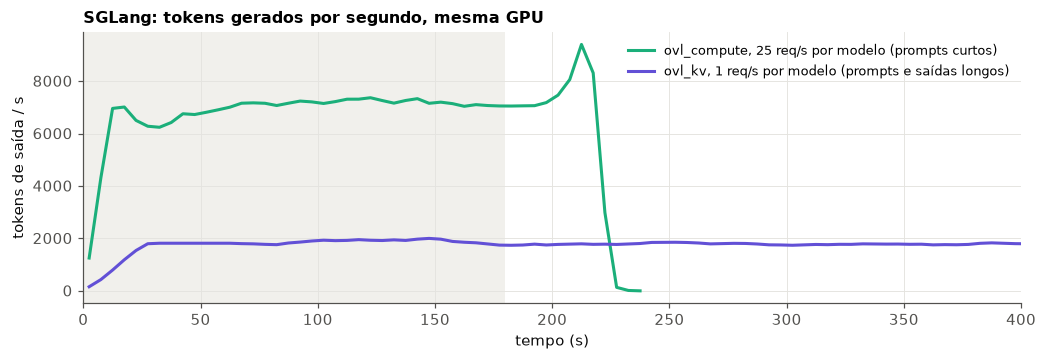

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.2))
kv1 = nivel("sglang", "ovl_kv", "1")
cp = nivel("sglang", "ovl_compute", "25")
for lv, cor, rot in ((cp, "#1baf7a", "ovl_compute, 25 req/s por modelo (prompts curtos)"),
                     (kv1, "#6250d6", "ovl_kv, 1 req/s por modelo (prompts e saídas longos)")):
    t = tokens_por_s(lv)
    ax.plot(t.t, t.saida, color=cor, label=rot)
janela(ax, kv1)
ax.set_xlim(0, 400)
ax.set_xlabel("tempo (s)")
ax.set_ylabel("tokens de saída / s")
ax.set_title("SGLang: tokens gerados por segundo, mesma GPU")
ax.legend(loc="upper right")
plt.show()

Com KV cheio, o SGLang gera ~1.900 tokens/s. Na mesma GPU, com requisições curtas, ele chega a ~7.000 (e a ~9.000 no esvaziamento, quando sobra só decode). **No `ovl_kv`, o limite é a memória de KV, não a computação:** a GPU teria capacidade para gerar mais, mas não cabem mais requisições no batch.

## Tabelas

A coluna "em regime" é a vazão sustentada (ver Convenções). O "atendido" do relatório aparece ao lado, para comparar.

In [16]:
tabela("ovl_kv", ["oferecido", "atendido", "em regime", "atendidas", "TTFT p50 (s)", "TTFT p99 (s)", "SLO",
                  "GPU pico (GB)", "retiradas"])

,backend,req/s por modelo,oferecido,atendido,em regime,atendidas,TTFT p50 (s),TTFT p99 (s),SLO,GPU pico (GB),retiradas
0,SGLang,0.25,1.02,0.74,0.77,184 / 184,0.34,0.54,100.0%,117.4,0
1,SGLang,0.50,1.87,0.96,0.95,337 / 337,18.12,94.09,36.2%,132.8,18
2,SGLang,1.00,3.99,1.09,1.08,718 / 718,178.44,423.47,15.7%,133.0,31
3,vLLM,0.25,1.02,0.80,0.90,184 / 184,0.32,0.90,98.9%,105.5,0
4,vLLM,0.50,1.87,1.26,1.27,337 / 337,0.41,42.14,58.2%,133.9,0
5,vLLM,1.00,3.99,1.45,1.56,718 / 718,99.16,257.69,20.8%,137.1,0


## Conclusões e limitações do Prism

- **A sobrecarga de KV não derruba o sistema.** Cada engine controla o próprio KV, e o excesso vira fila. Nenhuma requisição falhou ou ficou sem resposta, mesmo com o SGLang retirando requisições do batch 17 e 29 vezes (18 e 31 requisições, coluna "retiradas").
- **A diferença para o `ovl_mem` é a ativação.** Lá, o mesmo crescimento de KV derrubou o SGLang porque um modelo novo disputava a memória. Aqui, sem ativações, a pressão de KV é absorvida. O problema do `ovl_mem` é a decisão de ativar sem reserva, não o KV em si.
- **Sem controle de admissão, a latência cresce sem limite.** O GPU scheduler aceita tudo (`admission_control` usa `net_available = inf`, em `scheduling/gpu/request_queue.py:137`). A 1 req/s, o TTFT P99 chega a 423 s. Um controle de admissão que considerasse o KV disponível poderia recusar ou adiar requisições, em vez de deixá-las esperando minutos.
- **O limite de 40 GB por modelo não ajuda.** Os 4 limites somados (160 GB) passam muito da memória livre (~70 GB), então quem limita de fato é a memória física, disputada entre os engines.

**Limitações do teste.** Uma execução por nível. O "atendido" do relatório subestima a vazão nos níveis baixos (ver Convenções). O KV estimado supõe geração linear e ignora a fragmentação de páginas do kvcached.

## Por que o vLLM se comporta diferente

O vLLM teve **33% mais vazão no nível mais alto** (1,45 contra 1,09 req/s no "atendido") e TTFT bem menor a 0,5 req/s (0,41 contra 18 s de mediana). O plano de controle é o mesmo, e nenhum dos dois ativa ou despeja modelos durante a carga, então a diferença está nos engines.

- **Gerência do KV e preempção.** O vLLM V1 aloca o KV em blocos e, quando falta memória, preempta por recomputação a requisição mais recente. O SGLang 0.3.4 retira requisições do batch de decode e reduz a estimativa de tokens novos (`new_token_ratio`), o que o deixa mais conservador ao admitir requisições por um tempo.
- **Escalonamento de prefill.** O escalonador do vLLM V1 mistura prefill e decode no mesmo passo (chunked prefill), o que provavelmente explica boa parte do TTFT menor a 0,5 req/s. Não isolamos esse efeito.
- **Geração do engine.** O vLLM tem dois anos a mais de otimização, e os dois rodam sem CUDA graphs (`--disable-cuda-graph` no SGLang e `enforce_eager` no vLLM). Parte da diferença é do engine, não do desenho do Prism.

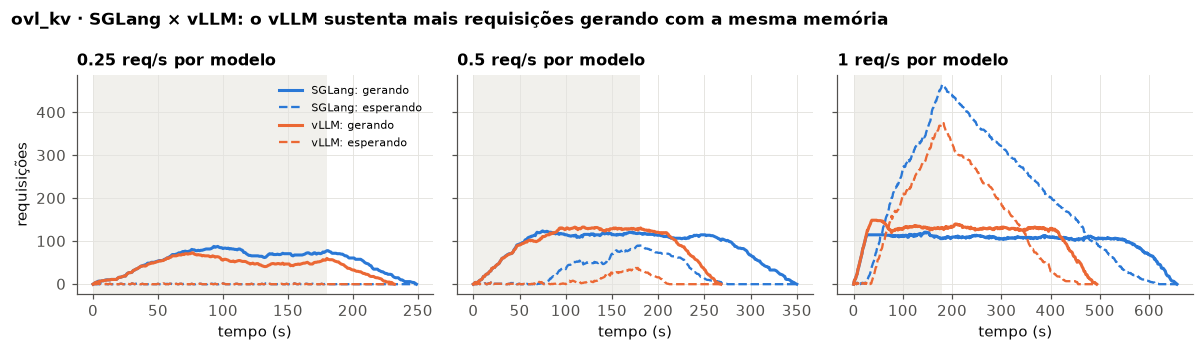

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, rate in zip(axs, niveis("vllm", "ovl_kv")):
    for b in ("sglang", "vllm"):
        a = andamento(nivel(b, "ovl_kv", rate))
        ax.plot(a.t, a.gerando, color=COR[b], label=f"{NOME[b]}: gerando")
        ax.plot(a.t, a.esperando, color=COR[b], ls="--", lw=1.5, label=f"{NOME[b]}: esperando")
    janela(ax, nivel("vllm", "ovl_kv", rate))
    ax.set_title(f"{rate} req/s por modelo")
    ax.set_xlabel("tempo (s)")
axs[0].set_ylabel("requisições")
axs[0].legend(loc="upper right", fontsize=7.5)
fig.suptitle("ovl_kv · SGLang × vLLM: o vLLM sustenta mais requisições gerando com a mesma memória",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

# 4. `ovl_compute`: mais requisições do que a GPU processa

## Objetivo

Isolar a **sobrecarga de computação**. Há poucos modelos, sem troca e com KV de sobra, e a taxa de chegada passa da capacidade da GPU. As perguntas são: onde fica a capacidade, o que o Prism faz com o excesso (recusa, descarta ou enfileira), e quanto a latência cresce.

## Como a sobrecarga foi montada

- **Modelos:** 2 × 8B, ambos ativos, com até 30 GB de KV cada (30 GB de pesos e ~5 GB de custo fixo, numa GPU de 139,7 GB).
- **Carga:** Poisson, 10, 12,5, 25 e 50 req/s por modelo (~20, 26, 50 e 100 req/s no total), cada nível por 120 s, com prazo de 300 s.

**Por que prompts de 256–768 tokens e saídas de 128–384.** O tamanho das requisições foi escolhido para que a computação seja o único gargalo:

- **O KV nunca enche.** Uma requisição média (512 de prompt + 256 de saída) ocupa ~0,1 GB de KV. Mesmo com centenas em andamento, o KV fica bem abaixo dos 60 GB permitidos aos dois modelos, ao contrário do `ovl_kv`.
- **Muitas requisições terminam dentro da janela.** Com saídas curtas, uma requisição dura poucos segundos, então a vazão é medida em regime, e não pelo esvaziamento.
- **É uma mistura realista.** O decode domina o custo de cada requisição (~256 passos contra 1 prefill), como numa carga de chat típica. As variantes `prefill` e `decode` da ampliação testam os dois extremos.
- **O trabalho é conhecido.** Com o tamanho exato (`ignore_eos`), tokens/s e req/s são comparáveis entre níveis e backends.

## Gráficos

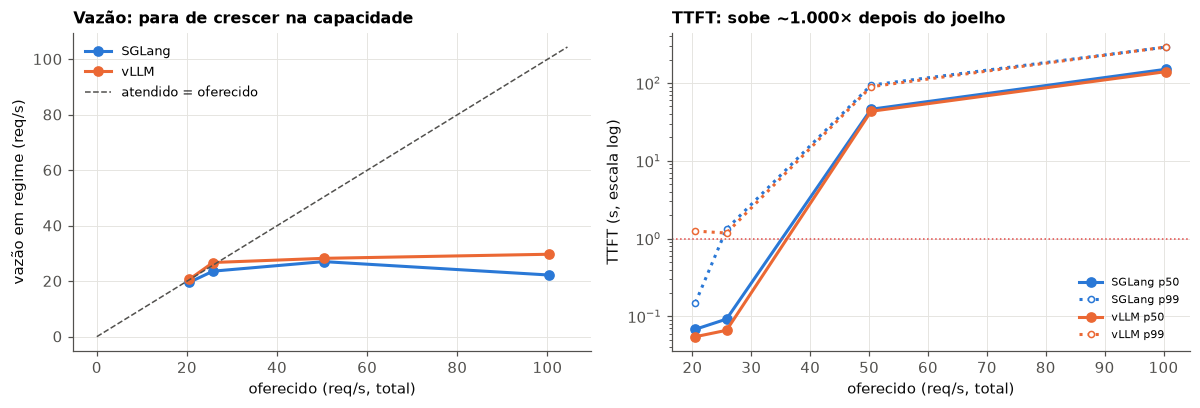

In [18]:
def curva(passos, ax_v, ax_t, backends=("sglang", "vllm"), estilo=None):
    for b in backends:
        for passo in passos:
            m = pd.DataFrame([metricas(nivel(b, passo, r)) for r in niveis(b, passo)])
            ls, mk = (estilo or {}).get(passo, ("-", "o"))
            ax_v.plot(m.oferecido, m["em regime"], ls=ls, marker=mk, color=COR[b], ms=6,
                      label=f"{NOME[b]}" + (f" · {passo}" if len(passos) > 1 else ""))
            ax_t.plot(m.oferecido, m["TTFT p50 (s)"], ls=ls, marker=mk, color=COR[b], ms=6,
                      label=f"{NOME[b]} p50" + (f" · {passo}" if len(passos) > 1 else ""))
            ax_t.plot(m.oferecido, m["TTFT p99 (s)"], ls=":", marker=mk, color=COR[b], ms=4, mfc="white",
                      label=f"{NOME[b]} p99" + (f" · {passo}" if len(passos) > 1 else ""))
    lim = ax_v.get_xlim()[1]
    ax_v.plot([0, lim], [0, lim], color=TINTA2, ls="--", lw=1, label="atendido = oferecido")
    ax_v.set_xlabel("oferecido (req/s, total)")
    ax_v.set_ylabel("vazão em regime (req/s)")
    ax_t.axhline(1, color=ERRO, ls=":", lw=1)
    ax_t.set_yscale("log")
    ax_t.set_xlabel("oferecido (req/s, total)")
    ax_t.set_ylabel("TTFT (s, escala log)")
    ax_v.legend(loc="upper left")
    ax_t.legend(loc="lower right", fontsize=7.5)


fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
curva(["ovl_compute"], axs[0], axs[1])
axs[0].set_title("Vazão: para de crescer na capacidade")
axs[1].set_title("TTFT: sobe ~1.000× depois do joelho")
fig.tight_layout()
plt.show()

A vazão acompanha a diagonal até ~25 req/s no SGLang e depois fica plana. O TTFT passa de ~0,1 s para dezenas de segundos assim que a oferta ultrapassa a capacidade, ou seja, não há degradação gradual. O gráfico abaixo mostra o porquê: acima da capacidade, a fila cresce linearmente durante toda a janela.

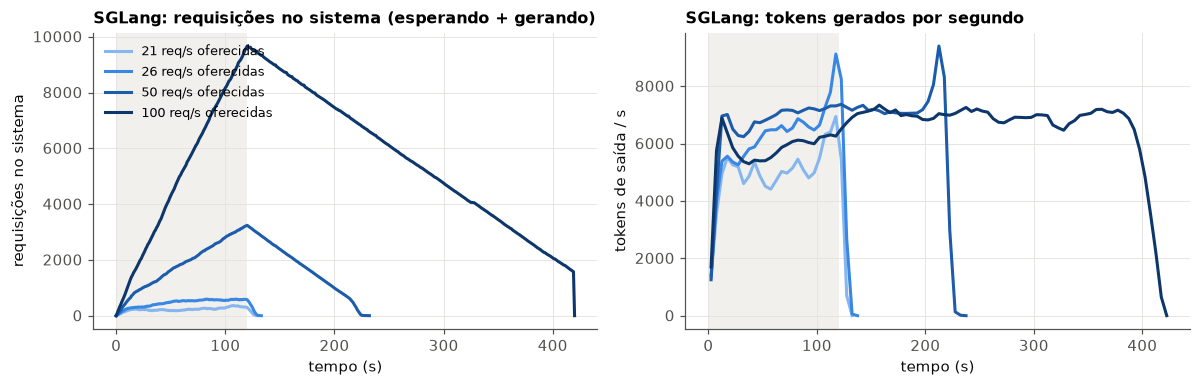

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for i, rate in enumerate(niveis("sglang", "ovl_compute")):
    lv = nivel("sglang", "ovl_compute", rate)
    a = andamento(lv)
    tot = lv["s"]["offered_rps"]
    axs[0].plot(a.t, a.esperando + a.gerando, color=AZUIS[i], label=f"{tot:.0f} req/s oferecidas")
    t = tokens_por_s(lv)
    axs[1].plot(t.t, t.saida, color=AZUIS[i], label=f"{tot:.0f} req/s oferecidas")
for ax in axs:
    janela(ax, lv)
    ax.set_xlabel("tempo (s)")
axs[0].set_ylabel("requisições no sistema")
axs[0].set_title("SGLang: requisições no sistema (esperando + gerando)")
axs[0].legend(loc="upper left")
axs[1].set_ylabel("tokens de saída / s")
axs[1].set_title("SGLang: tokens gerados por segundo")
fig.tight_layout()
plt.show()

A ~20 e ~26 req/s, o sistema fica estável, com poucas centenas de requisições em andamento. A ~50 e ~100 req/s, as requisições se acumulam sem limite: a 100 req/s, eram ~9.700 no fim da janela, e 1.560 ainda esperavam no fim do prazo. Enquanto isso, os tokens/s ficam no mesmo teto (~7.000 tokens/s), qualquer que seja a oferta. A GPU está no limite, e o excesso só aumenta a fila. O relatório cita ~6.400 tokens/s porque divide pelo tempo total, incluindo o esvaziamento.

## Tabelas

In [20]:
tabela("ovl_compute", ["oferecido", "atendido", "em regime", "atendidas", "não atendidas", "TTFT p50 (s)",
                       "TTFT p99 (s)", "TPOT médio (ms)", "SLO", "GPU pico (GB)"])

,backend,req/s por modelo,oferecido,atendido,em regime,atendidas,não atendidas,TTFT p50 (s),TTFT p99 (s),TPOT médio (ms),SLO,GPU pico (GB)
0,SGLang,10.0,20.52,19.12,19.59,2462 / 2462,0,0.07,0.15,44.77,100.0%,68.8
1,SGLang,12.5,25.78,23.31,23.62,3094 / 3094,0,0.09,1.32,72.10,96.6%,93.0
2,SGLang,25.0,50.33,26.07,27.07,6040 / 6040,0,46.01,93.99,81.89,9.6%,86.3
3,SGLang,50.0,100.44,24.97,22.22,10493 / 12053,1560,150.40,290.53,88.83,1.1%,87.4
4,vLLM,10.0,20.52,19.64,20.64,2462 / 2462,0,0.05,1.25,22.96,98.1%,49.4
5,vLLM,12.5,25.78,24.50,26.74,3094 / 3094,0,0.07,1.18,27.91,98.6%,55.5
6,vLLM,25.0,50.33,27.93,28.24,6040 / 6040,0,43.30,89.71,34.20,4.3%,56.4
7,vLLM,50.0,100.44,28.61,29.72,12015 / 12053,38,140.19,290.61,34.19,2.1%,60.0


## Ampliação dos testes de computação

Sete variações do `ovl_compute`, cada uma nos dois backends, para entender melhor a capacidade e o que a afeta.

### `fine`: onde fica o joelho?

São 2 × 8B, de 20 a 40 req/s em passos de ~2,5, com a mesma carga do `ovl_compute`.

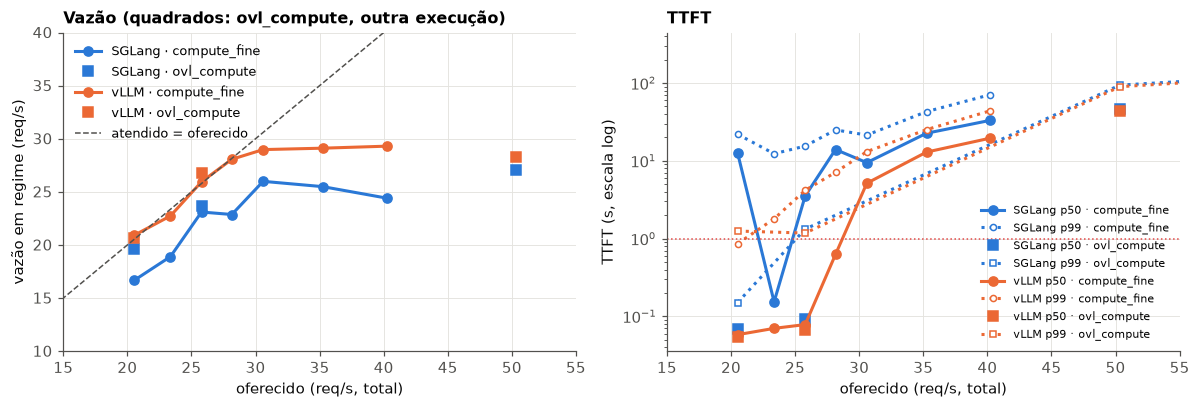

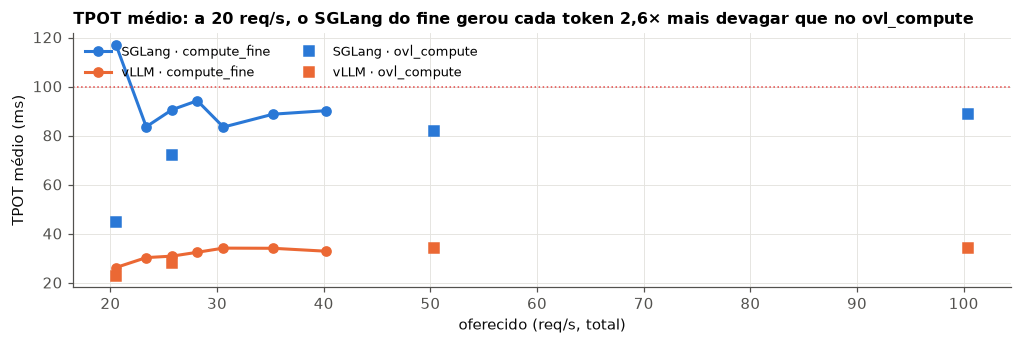

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
curva(["compute_fine", "ovl_compute"], axs[0], axs[1], estilo={"ovl_compute": ("none", "s")})
axs[0].set_xlim(15, 55)
axs[0].set_ylim(10, 40)
axs[0].set_title("Vazão (quadrados: ovl_compute, outra execução)")
axs[1].set_xlim(15, 55)
axs[1].set_title("TTFT")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3))
for passo, mk in (("compute_fine", "o"), ("ovl_compute", "s")):
    for b in ("sglang", "vllm"):
        m = pd.DataFrame([metricas(nivel(b, passo, r)) for r in niveis(b, passo)])
        ax.plot(m.oferecido, m["TPOT médio (ms)"], marker=mk, ls="-" if mk == "o" else "none", color=COR[b],
                label=f"{NOME[b]} · {passo}")
ax.axhline(100, color=ERRO, ls=":", lw=1)
ax.set_xlabel("oferecido (req/s, total)")
ax.set_ylabel("TPOT médio (ms)")
ax.set_title("TPOT médio: a 20 req/s, o SGLang do fine gerou cada token 2,6× mais devagar que no ovl_compute")
ax.legend(loc="upper left", ncol=2)
plt.show()

**No vLLM**, o joelho fica entre 26 e 28 req/s: o SLO cai de 80% para 57% a 28 req/s e para 7% a 31 req/s, e a vazão estabiliza em ~28 req/s.

**No SGLang, o resultado não é confiável.** A 20,5 req/s, o `fine` teve TTFT mediano de 12 s e SLO de 0%. A mesma carga, com as mesmas chegadas e a mesma config, no `ovl_compute` teve 0,07 s e 100%. A curva nem é monótona: a 23 req/s, o `fine` foi melhor que a 20,5. O TPOT mostra a causa: a 20,5 req/s, o SGLang do `fine` gerou cada token em 117 ms em média, contra 45 ms no `ovl_compute`. Os dois jobs rodaram em H200 diferentes do cluster. O vLLM não teve essa variação. Antes de tirar conclusões sobre o joelho do SGLang, precisamos repetir o `fine` e registrar o nó e o estado da GPU em cada job.

Vale notar também que, com carga, o TPOT do SGLang fica em 80–90 ms, perto do SLO de 100 ms. O do vLLM fica em ~30 ms.

### `sustained`: ficar muito tempo acima da capacidade derruba o sistema?

São 2 × 8B a 37,5 req/s (~1,5× a capacidade) durante 10 minutos.

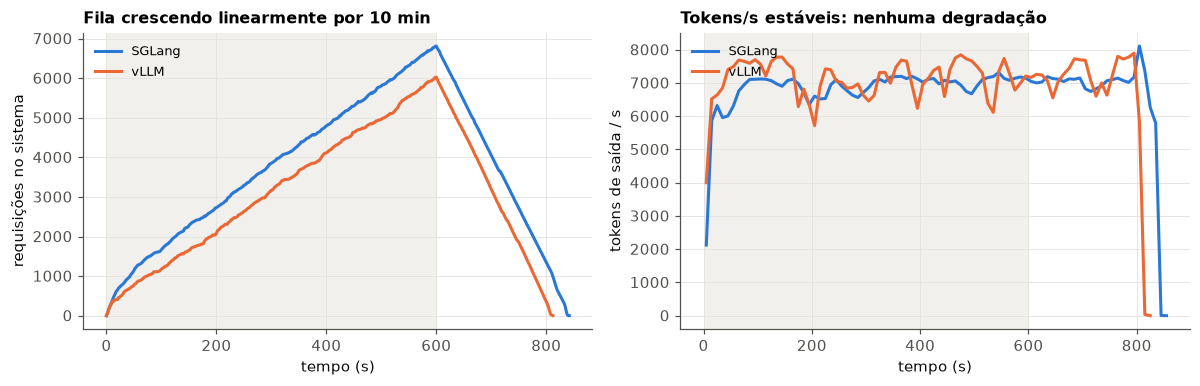

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for b in ("sglang", "vllm"):
    lv = nivel(b, "compute_sustained", "18.75")
    a = andamento(lv, dt=2)
    axs[0].plot(a.t, a.esperando + a.gerando, color=COR[b], label=NOME[b])
    t = tokens_por_s(lv, dt=10)
    axs[1].plot(t.t, t.saida, color=COR[b], label=NOME[b])
for ax in axs:
    janela(ax, lv)
    ax.set_xlabel("tempo (s)")
    ax.legend(loc="upper left")
axs[0].set_ylabel("requisições no sistema")
axs[0].set_title("Fila crescendo linearmente por 10 min")
axs[1].set_ylabel("tokens de saída / s")
axs[1].set_title("Tokens/s estáveis: nenhuma degradação")
fig.tight_layout()
plt.show()

Depois de 10 minutos acima da capacidade, ~6.800 requisições estavam acumuladas no SGLang (~6.000 no vLLM). Ainda assim, nenhuma falhou, e tudo foi atendido no prazo. Os tokens/s ficam estáveis o tempo todo, então o sistema não degrada nem cai. A conta é simples: a fila cresce na diferença entre o oferecido e a capacidade (~10 req/s), e o TTFT cresce junto (P99 de 238 s no SGLang).

### `models4` e `models6`: dividir a GPU entre mais modelos ativos reduz a capacidade?

São 4 e 6 modelos 8B ativos, com a mesma carga total de 20, 30 e 40 req/s dividida entre eles. Com 6 modelos, o KV de cada um é limitado a 15 GB.

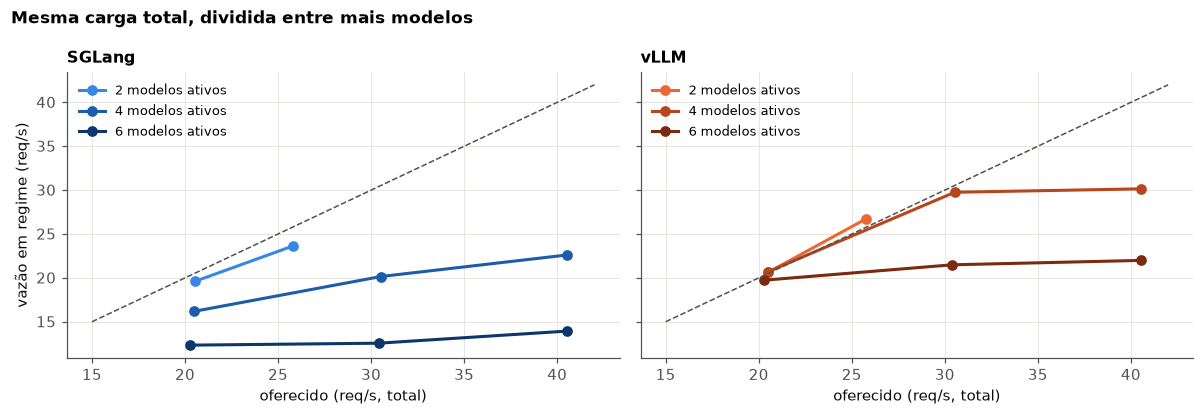

,backend,req/s por modelo,oferecido,em regime,TTFT p50 (s),SLO,GPU pico (GB),retiradas
0,SGLang,3.333,20.27,12.33,42.29,0.0%,132.8,30
1,SGLang,5.000,30.40,12.56,76.11,3.6%,132.8,48
2,SGLang,6.667,40.52,13.93,113.53,4.4%,133.0,55
3,vLLM,3.333,20.27,19.73,0.14,97.7%,132.4,0
4,vLLM,5.000,30.40,21.49,18.65,13.9%,134.4,0
5,vLLM,6.667,40.52,21.99,42.98,9.9%,134.2,0


In [23]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, b, cores in ((axs[0], "sglang", AZUIS), (axs[1], "vllm", LARANJAS)):
    for i, (passo, n) in enumerate((("ovl_compute", 2), ("compute_models4", 4), ("compute_models6", 6))):
        m = pd.DataFrame([metricas(nivel(b, passo, r)) for r in niveis(b, passo)])
        m = m[m.oferecido < 45]
        ax.plot(m.oferecido, m["em regime"], marker="o", color=cores[i + 1], label=f"{n} modelos ativos")
    ax.plot([15, 42], [15, 42], color=TINTA2, ls="--", lw=1)
    ax.set_title(NOME[b])
    ax.set_xlabel("oferecido (req/s, total)")
    ax.legend(loc="upper left")
axs[0].set_ylabel("vazão em regime (req/s)")
fig.suptitle("Mesma carga total, dividida entre mais modelos", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

tabela("compute_models6", ["oferecido", "em regime", "TTFT p50 (s)", "SLO", "GPU pico (GB)", "retiradas"])

- **SGLang:** com 4 modelos, a capacidade cai pouco (~23 contra ~25 req/s). **Com 6 modelos, cai quase pela metade** (~13–14 req/s).
- **vLLM:** com 4 modelos, não perde nada (~30 req/s). Com 6, cai para ~22.

A causa principal parece ser a **memória**, não a computação. Com 6 modelos, os pesos ocupam 90 GB, e sobra pouco KV para cada engine. A GPU fica cheia nos dois backends (133–134 GB), e o SGLang retira 30 a 55 requisições do batch por falta de KV. Com a carga dividida, os batches por modelo também ficam menores, mas o teste não separa os dois efeitos. **Para o Prism, isso importa**: colocar mais modelos na mesma GPU custa vazão, mesmo sem nenhuma troca de modelo.

### `prefill` e `decode`: muda o gargalo?

Para isolar cada fase, há duas variantes com 2 × 8B:

- **`prefill`:** prompts de 3.000–4.000 tokens e saídas de 16–64.
- **`decode`:** prompts de 32–128 tokens e saídas de 1.024–2.048.

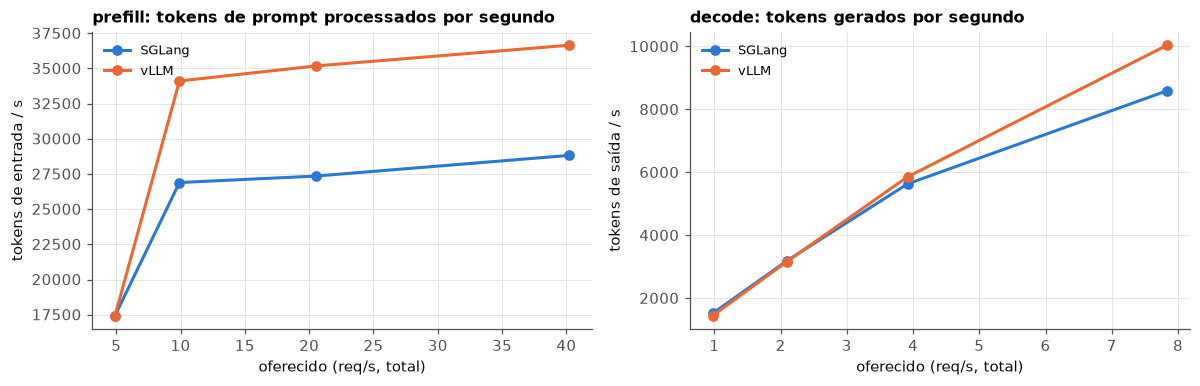

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for b in ("sglang", "vllm"):
    for ax, passo, col, rot in ((axs[0], "compute_prefill", "entrada", "tokens de entrada / s"),
                                (axs[1], "compute_decode", "saida", "tokens de saída / s")):
        xs, ys = [], []
        for r in niveis(b, passo):
            lv = nivel(b, passo, r)
            t = tokens_por_s(lv, dt=5)
            dur = lv["s"]["args"]["duration"]
            xs.append(lv["s"]["offered_rps"])
            ys.append(t[(t.t > 0.25 * dur) & (t.t < dur)][col].mean())
        ax.plot(xs, ys, marker="o", color=COR[b], label=NOME[b])
        ax.set_ylabel(rot)
        ax.set_xlabel("oferecido (req/s, total)")
axs[0].set_title("prefill: tokens de prompt processados por segundo")
axs[1].set_title("decode: tokens gerados por segundo")
for ax in axs:
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

- **Prefill:** o SGLang processa ~27–29 mil tokens de prompt por segundo e atende no máximo ~8 req/s. O vLLM processa ~34–37 mil e atende ~10 req/s. A 40 req/s, sobram requisições não atendidas no prazo (1.473 no SGLang e 548 no vLLM).
- **Decode:** a ~8 req/s, o vLLM gera ~10.000 tokens/s e o SGLang ~8.600, com TTFT P99 de 22 s no SGLang. Com prompts curtos, o batch de decode pode crescer bastante, então o decode rende mais tokens/s que a carga mista do `ovl_compute`. Mesmo assim, o SGLang já está acima da capacidade nesse nível.

Nos dois extremos, o comportamento acima da capacidade é o mesmo: a fila cresce, e nada é recusado.

### `bursty`: rajadas sobrecarregam mesmo com média abaixo da capacidade?

São 2 × 8B com a carga do `ovl_compute`, mas com chegadas em rajadas: gamma com coeficiente de variação 4 (o Poisson tem 1). A média é de 15 e 20 req/s, abaixo da capacidade. A comparação é com o `ovl_compute` a 20 req/s, que tem a mesma média e chegadas Poisson.

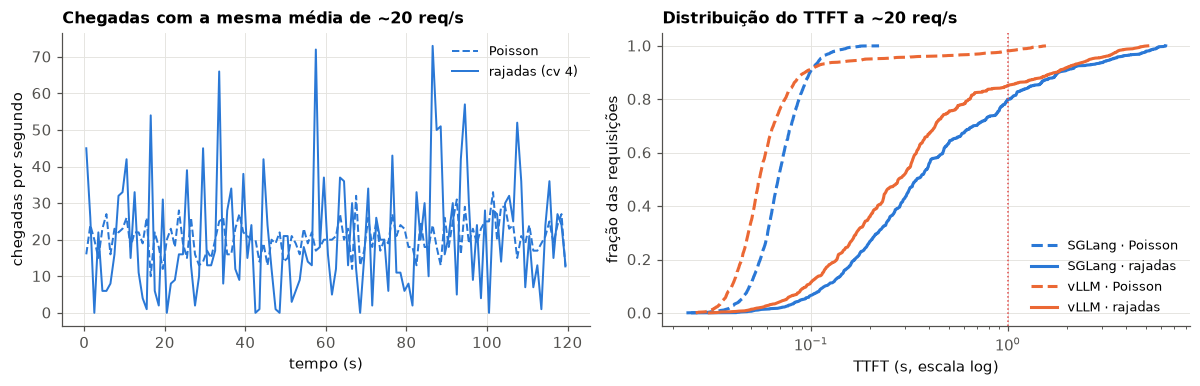

,backend,req/s por modelo,oferecido,em regime,TTFT p50 (s),TTFT p99 (s),SLO
0,SGLang,7.5,15.82,13.84,0.28,1.50,93.5%
1,SGLang,10.0,20.58,17.14,0.35,5.68,76.7%
2,vLLM,7.5,15.82,14.19,0.20,1.23,98.3%
3,vLLM,10.0,20.58,20.77,0.28,4.35,85.1%


In [25]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for lv, ls, rot in ((nivel("sglang", "ovl_compute", "10"), "--", "Poisson"),
                    (nivel("sglang", "compute_bursty", "10"), "-", "rajadas (cv 4)")):
    c = np.histogram(lv["req"].arrival, bins=np.arange(0, 121, 1))[0]
    axs[0].plot(np.arange(0.5, 120), c, ls=ls, lw=1.3, color=COR["sglang"], label=rot)
axs[0].set_xlabel("tempo (s)")
axs[0].set_ylabel("chegadas por segundo")
axs[0].set_title("Chegadas com a mesma média de ~20 req/s")
axs[0].legend(loc="upper right")
for b in ("sglang", "vllm"):
    for passo, ls, rot in (("ovl_compute", "--", "Poisson"), ("compute_bursty", "-", "rajadas")):
        tt = np.sort(nivel(b, passo, "10")["req"].ttft.dropna().values)
        axs[1].plot(tt, np.arange(1, len(tt) + 1) / len(tt), ls=ls, color=COR[b], label=f"{NOME[b]} · {rot}")
axs[1].axvline(1, color=ERRO, ls=":", lw=1)
axs[1].set_xscale("log")
axs[1].set_xlabel("TTFT (s, escala log)")
axs[1].set_ylabel("fração das requisições")
axs[1].set_title("Distribuição do TTFT a ~20 req/s")
axs[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

tabela("compute_bursty", ["oferecido", "em regime", "TTFT p50 (s)", "TTFT p99 (s)", "SLO"])

**Sim.** Com a mesma média de ~20 req/s, as rajadas derrubam o SLO do SGLang de 100% para 77% e levam o TTFT P99 de 0,15 s para 5,7 s. Durante cada rajada, a taxa instantânea passa da capacidade e forma uma fila temporária, que só esvazia na calmaria seguinte. A capacidade média não basta: é preciso folga para os picos. Um controle de admissão também ajudaria aqui.

## Conclusões e limitações do Prism

- **A capacidade de uma H200 com 2 × 8B e carga mista fica em ~25 req/s no SGLang** (~7.000 tokens/s) e em ~28 req/s no vLLM. Ela cai com mais modelos ativos na mesma GPU, quase pela metade no SGLang com 6 modelos.
- **Acima da capacidade, tudo vira fila.** O Prism não tem controle de admissão (`net_available = inf`), então não recusa nem adia nada, e o TTFT cresce sem limite. O sistema não cai nem degrada, nem depois de 10 min a 1,5× a capacidade, mas a latência deixa de ser útil.
- **Rajadas sobrecarregam mesmo com média abaixo da capacidade.** A métrica que importa é o pico, não a média.

**Limitações do teste.** Uma execução por nível. A variação entre jobs do SGLang (`fine` contra `ovl_compute`) mostra que uma execução não basta para localizar o joelho. Nos testes com 4 e 6 modelos, a memória também pesa, então eles não medem só computação.

## Por que o vLLM se comporta diferente

O vLLM tem ~10–15% mais capacidade com 2 modelos (28 contra 25 req/s), ~60% mais com 6 modelos (22 contra 13–14), ~30% mais no prefill, e TPOT 2–3× menor com carga (~30 contra 80–90 ms). O plano de controle não participa desse cenário (não há trocas), então tudo vem do engine:

- **Kernels e escalonador mais novos** (2026 contra 2024): o escalonador V1 com chunked prefill não interrompe o decode para fazer prefills longos, o que ajuda principalmente no `prefill` e nas rajadas.
- **Memória.** Com a mesma carga, o vLLM usa bem menos memória (pico de 56 GB contra 86 GB no `fine`). Com 4 e 6 modelos, o SGLang esgota o KV e retira requisições; o vLLM não.
- **Os dois rodam sem CUDA graphs**, então essa diferença não explica a vantagem do vLLM.

Como o comportamento acima da capacidade é igual nos dois (fila sem limite e nenhuma recusa), **a limitação de controle de admissão é do Prism, não do engine**.

# 5. Síntese: limitações do Prism observadas

| Limitação | Onde aparece | Efeito no SGLang | Efeito no vLLM |
| --- | --- | --- | --- |
| Só despeja modelos ociosos há mais de 50 s (limiar fixo no código) | `ovl_mem`, `ovl_phases` | 3 modelos sem atendimento; transições com P99 de ~53 s | os mesmos 3 esperam ~6 min; transições com P99 de ~50 s |
| Ativa olhando só a memória livre do instante, sem reservar KV | `ovl_mem` | ativações falham no kvcached | ativações bloqueiam até haver memória |
| Ativação que falha não é reportada ao controlador | `ovl_mem` | modelos pendurados em `activating` para sempre | não ocorre (a ativação espera) |
| Um worker sem memória derruba o servidor | `ovl_mem` 0,5 req/s | queda total aos ~10 s | não ocorre |
| Sem controle de admissão | `ovl_kv`, `ovl_compute` | fila e TTFT sem limite | igual |
| Mais modelos ativos na mesma GPU reduzem a vazão | `models4`/`models6` | 6 modelos: ~13 contra ~25 req/s | 6 modelos: ~22 contra ~28 req/s (4 modelos: sem perda) |

**O que mudaria esse quadro:**

1. Despejar modelos ocupados (ou ociosos há menos de 50 s) quando um modelo com fila não cabe.
2. Reservar memória para o KV ao ativar.
3. Avisar o controlador quando uma ativação falha.
4. Ter controle de admissão no GPU scheduler.